# California Housing — Exploratory Data Analysis & Price Prediction

**Goal:** understand what drives median house values in California districts and build a model that predicts them.

**Data:** 1990 U.S. Census, one row per census block group (20,640 districts), 9 features + target `median_house_value`.
Source: Pace & Barry (1997), *Sparse Spatial Autoregressions*; version with `ocean_proximity` from A. Géron, *Hands-On Machine Learning*.

**Contents**
1. Data overview & quality checks
2. Exploratory analysis — distribution, geography, ocean proximity, income
3. Feature engineering
4. Modeling — 7 regression models compared on the same split
5. Best model — errors and feature importance
6. Key findings

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_theme(style="whitegrid", context="notebook")
PALETTE = ["#2a6f97", "#e07a5f", "#81b29a", "#f2cc8f", "#3d405b", "#9c89b8", "#61a5c2"]
FIG = "figures/"
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

## 1. Data overview & quality checks

In [2]:
df = pd.read_csv("data/housing.csv")
print(f"{df.shape[0]:,} rows × {df.shape[1]} columns")
df.head()

20,640 rows × 10 columns


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.00,880.00,129.00,322.00,126.00,8.33,"452,600.00",NEAR BAY
1,-122.22,37.86,21.00,"7,099.00","1,106.00","2,401.00","1,138.00",8.30,"358,500.00",NEAR BAY
2,-122.24,37.85,52.00,"1,467.00",190.00,496.00,177.00,7.26,"352,100.00",NEAR BAY
3,-122.25,37.85,52.00,"1,274.00",235.00,558.00,219.00,5.64,"341,300.00",NEAR BAY
4,-122.25,37.85,52.00,"1,627.00",280.00,565.00,259.00,3.85,"342,200.00",NEAR BAY


In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
longitude,"20,640.00",-119.57,2.00,-124.35,-121.80,-118.49,-118.01,-114.31
latitude,"20,640.00",35.63,2.14,32.54,33.93,34.26,37.71,41.95
housing_median_age,"20,640.00",28.64,12.59,1.00,18.00,29.00,37.00,52.00
total_rooms,"20,640.00","2,635.76","2,181.62",2.00,"1,447.75","2,127.00","3,148.00","39,320.00"
total_bedrooms,"20,433.00",537.87,421.39,1.00,296.00,435.00,647.00,"6,445.00"
population,"20,640.00","1,425.48","1,132.46",3.00,787.00,"1,166.00","1,725.00","35,682.00"
households,"20,640.00",499.54,382.33,1.00,280.00,409.00,605.00,"6,082.00"
median_income,"20,640.00",3.87,1.90,0.50,2.56,3.53,4.74,15.00
median_house_value,"20,640.00","206,855.82","115,395.62","14,999.00","119,600.00","179,700.00","264,725.00","500,001.00"


In [4]:
quality = pd.DataFrame({
    "missing": df.isnull().sum(),
    "missing_%": (df.isnull().mean() * 100).round(2),
    "dtype": df.dtypes.astype(str),
})
quality[quality["missing"] > 0]

,missing,missing_%,dtype
total_bedrooms,207,1.00,float64


In [5]:
caps = {
    "median_house_value = 500,001 (top-coded)": (df["median_house_value"] >= 500_001).sum(),
    "housing_median_age = 52 (top-coded)": (df["housing_median_age"] == 52).sum(),
    "median_income ≥ 15 (top-coded)": (df["median_income"] >= 15).sum(),
}
pd.Series(caps, name="districts").to_frame()

,districts
"median_house_value = 500,001 (top-coded)",965
housing_median_age = 52 (top-coded),1273
median_income ≥ 15 (top-coded),51


**Data quality notes**
- `total_bedrooms` has 207 missing values (1%). They are imputed with the **median, learned on the training set only** (inside the pipeline) to avoid leakage.
- Three columns are **top-coded** by the census: 965 districts sit exactly at the \$500,001 price cap. Models cannot predict above this value, which limits accuracy for the most expensive areas.
- `median_income` is expressed in tens of thousands of USD (e.g. 3.5 ≈ \$35,000).

## 2. Exploratory analysis

### 2.1 Distribution of house values

Median: $179,700 · Mean: $206,856


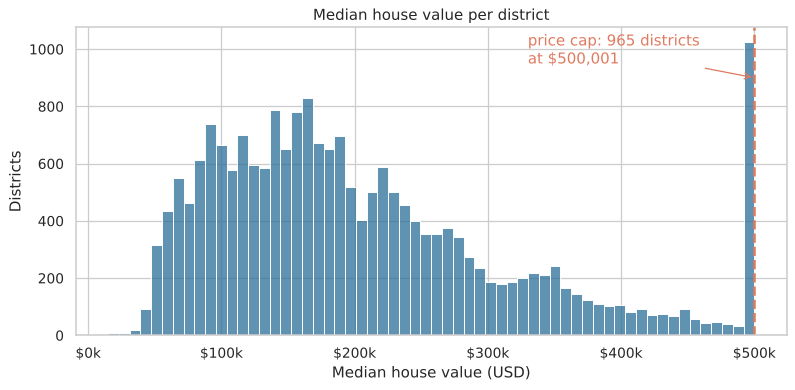

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(df["median_house_value"], bins=60, color=PALETTE[0], ax=ax)
ax.axvline(500_001, color=PALETTE[1], ls="--", lw=2)
ax.annotate("price cap: 965 districts\nat $500,001", xy=(500_001, 900), xytext=(330_000, 950),
            arrowprops=dict(arrowstyle="->", color=PALETTE[1]), color=PALETTE[1])
ax.set(title="Median house value per district", xlabel="Median house value (USD)", ylabel="Districts")
ax.xaxis.set_major_formatter(lambda v, _: f"${v/1000:,.0f}k")
plt.tight_layout(); plt.savefig(FIG + "01_price_distribution.png", dpi=150); plt.show()
print(f"Median: ${df.median_house_value.median():,.0f} · Mean: ${df.median_house_value.mean():,.0f}")

The distribution is right-skewed (mean > median) with a hard spike at the cap.

### 2.2 Geography: where are the expensive districts?

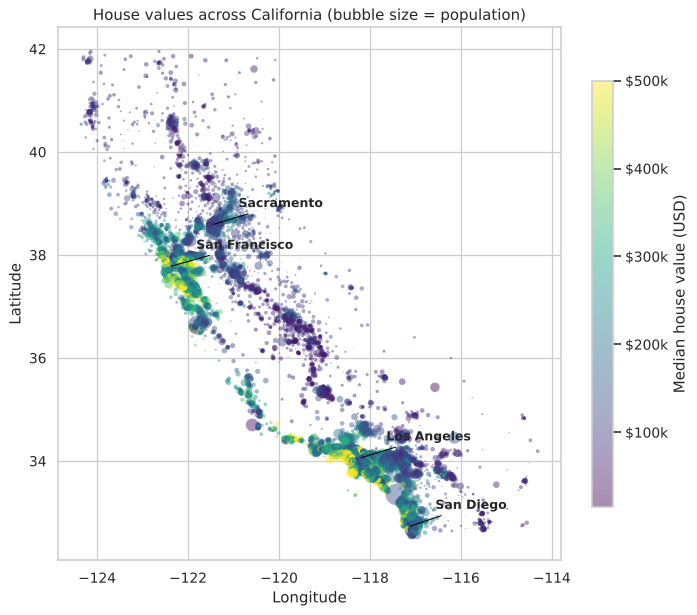

In [7]:
fig, ax = plt.subplots(figsize=(8, 7))
sc = ax.scatter(df["longitude"], df["latitude"], c=df["median_house_value"], s=df["population"] / 120,
                cmap="viridis", alpha=0.45, linewidths=0)
cb = plt.colorbar(sc, ax=ax, shrink=0.8); cb.set_label("Median house value (USD)")
cb.ax.yaxis.set_major_formatter(lambda v, _: f"${v/1000:,.0f}k")
for name, (lon, lat) in {"San Francisco": (-122.42, 37.77), "Los Angeles": (-118.24, 34.05),
                         "San Diego": (-117.16, 32.72), "Sacramento": (-121.49, 38.58)}.items():
    ax.annotate(name, (lon, lat), xytext=(lon + 0.6, lat + 0.35), fontsize=10, weight="bold",
                arrowprops=dict(arrowstyle="-", color="black", lw=0.8))
ax.set(title="House values across California (bubble size = population)", xlabel="Longitude", ylabel="Latitude")
plt.tight_layout(); plt.savefig(FIG + "02_geographic_map.png", dpi=150); plt.show()

Prices cluster along the coast — the **San Francisco Bay Area** and **Los Angeles / San Diego** — and fall sharply inland.

### 2.3 Ocean proximity

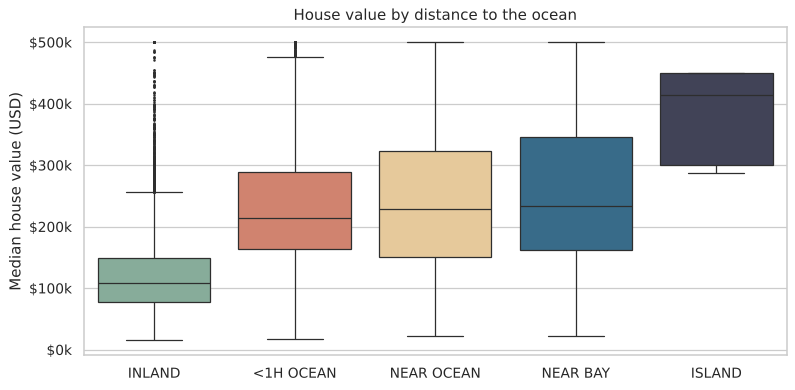

,districts,median,mean
ocean_proximity,,,
INLAND,6551,"108,500.00","124,805.39"
<1H OCEAN,9136,"214,850.00","240,084.29"
NEAR OCEAN,2658,"229,450.00","249,433.98"
NEAR BAY,2290,"233,800.00","259,212.31"
ISLAND,5,"414,700.00","380,440.00"


In [8]:
order = df.groupby("ocean_proximity")["median_house_value"].median().sort_values().index
summary = (df.groupby("ocean_proximity")["median_house_value"]
             .agg(districts="count", median="median", mean="mean").loc[order])
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=df, x="ocean_proximity", y="median_house_value", order=order, palette=PALETTE[:5],
            hue="ocean_proximity", legend=False, fliersize=1, ax=ax)
ax.set(title="House value by distance to the ocean", xlabel="", ylabel="Median house value (USD)")
ax.yaxis.set_major_formatter(lambda v, _: f"${v/1000:,.0f}k")
plt.tight_layout(); plt.savefig(FIG + "03_ocean_proximity.png", dpi=150); plt.show()
summary

In [9]:
inland = summary.loc["INLAND", "median"]
coastal = df[df.ocean_proximity.isin(["<1H OCEAN", "NEAR OCEAN", "NEAR BAY"])]["median_house_value"].median()
print(f"Coastal districts are {coastal / inland:.1f}× more expensive than inland ones (median ${coastal:,.0f} vs ${inland:,.0f}).")

Coastal districts are 2.0× more expensive than inland ones (median $219,400 vs $108,500).


`ISLAND` has only 5 districts, so its high median is not statistically reliable.

### 2.4 Income — the strongest single driver

Highest-income districts: 3.2× the median value of the lowest-income ones.


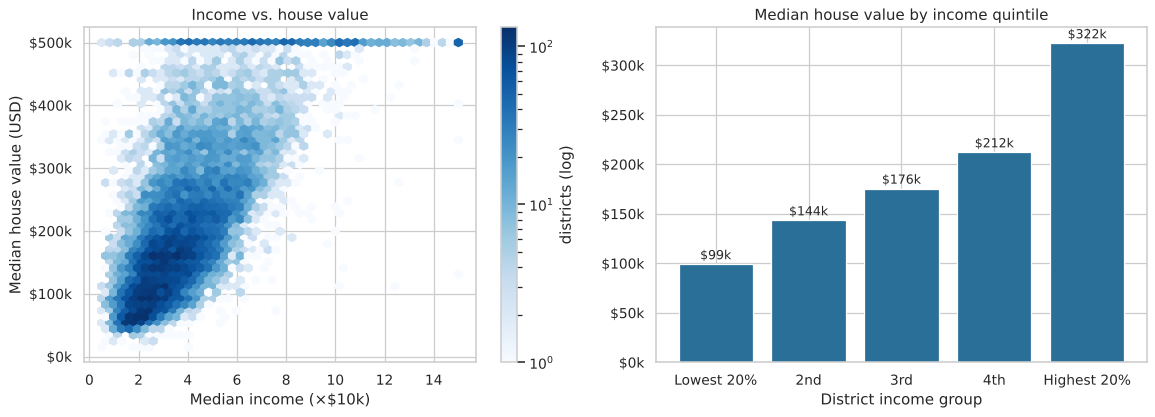

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
hb = axes[0].hexbin(df["median_income"], df["median_house_value"], gridsize=45, cmap="Blues", mincnt=1, bins="log")
axes[0].set(title="Income vs. house value", xlabel="Median income (×$10k)", ylabel="Median house value (USD)")
axes[0].yaxis.set_major_formatter(lambda v, _: f"${v/1000:,.0f}k")
plt.colorbar(hb, ax=axes[0], label="districts (log)")

q = pd.qcut(df["median_income"], 5, labels=["Lowest 20%", "2nd", "3rd", "4th", "Highest 20%"])
by_q = df.groupby(q, observed=True)["median_house_value"].median()
axes[1].bar(by_q.index.astype(str), by_q.values, color=PALETTE[0])
for i, v in enumerate(by_q.values):
    axes[1].text(i, v + 5000, f"${v/1000:,.0f}k", ha="center", fontsize=10)
axes[1].set(title="Median house value by income quintile", xlabel="District income group", ylabel="")
axes[1].yaxis.set_major_formatter(lambda v, _: f"${v/1000:,.0f}k")
plt.tight_layout(); plt.savefig(FIG + "04_income.png", dpi=150); plt.show()
print(f"Highest-income districts: {by_q.iloc[-1] / by_q.iloc[0]:.1f}× the median value of the lowest-income ones.")

### 2.5 Correlations

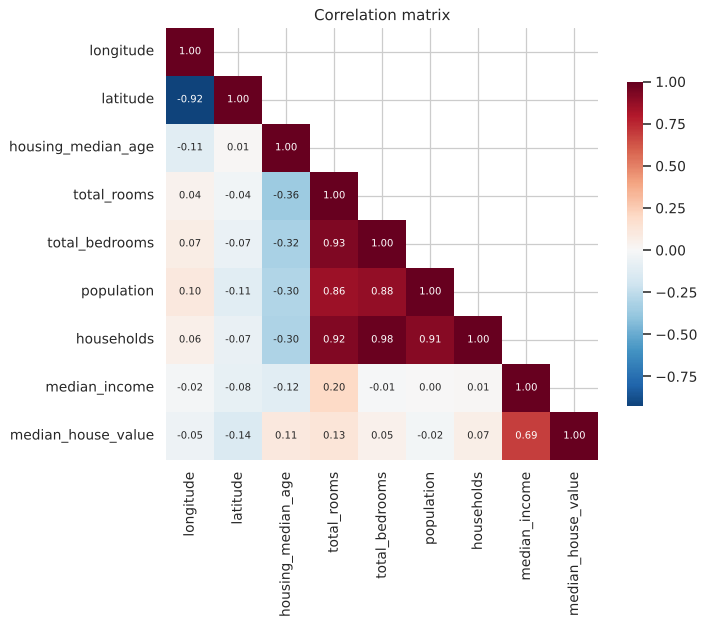

,correlation with price
median_income,0.69
total_rooms,0.13
housing_median_age,0.11
households,0.07
total_bedrooms,0.05
population,-0.02
longitude,-0.05
latitude,-0.14


In [11]:
corr = df.drop(columns="ocean_proximity").corr()
fig, ax = plt.subplots(figsize=(8.5, 7))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True,
            cbar_kws={"shrink": 0.75}, annot_kws={"size": 8}, ax=ax)
ax.set_title("Correlation matrix")
plt.tight_layout(); plt.savefig(FIG + "05_correlations.png", dpi=150); plt.show()
corr["median_house_value"].drop("median_house_value").sort_values(ascending=False).to_frame("correlation with price")

- `median_income` correlates strongly with price (**r = 0.69**); every other raw feature is weak (|r| < 0.15).
- `total_rooms`, `total_bedrooms`, `population` and `households` are almost collinear (r > 0.85) — they all measure **district size**, not housing quality. This motivates ratio features.

## 3. Feature engineering

In [12]:
def add_features(d):
    d = d.copy()
    d["rooms_per_household"] = d["total_rooms"] / d["households"]
    d["bedrooms_per_room"] = d["total_bedrooms"] / d["total_rooms"]
    d["population_per_household"] = d["population"] / d["households"]
    return d

eng = add_features(df)
new = ["rooms_per_household", "bedrooms_per_room", "population_per_household"]
eng[new + ["median_house_value"]].corr()["median_house_value"].drop("median_house_value").to_frame("correlation with price")

,correlation with price
rooms_per_household,0.15
bedrooms_per_room,-0.26
population_per_household,-0.02


`bedrooms_per_room` (r = −0.26) is far more informative than raw `total_bedrooms` (r = 0.05): districts where a larger share of rooms are bedrooms (smaller homes) are cheaper.

## 4. Modeling

**Setup**
- 80/20 train/test split, **stratified by income quintile** so both sets have the same income mix.
- One preprocessing pipeline for every model: ratio features → median imputation → scaling (for linear models and SVR) → one-hot encoding of `ocean_proximity` (no false ordering of categories).
- Hyperparameters tuned with cross-validation **on the training set only**; the test set is used once, for the final comparison.
- Metrics: **RMSE** and **MAE** in USD, and **R²**.

In [13]:
y = df["median_house_value"]
X = df.drop(columns="median_house_value")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=pd.qcut(X["median_income"], 5, labels=False))

NUM = ["longitude", "latitude", "housing_median_age", "total_rooms", "total_bedrooms", "population",
       "households", "median_income", "rooms_per_household", "bedrooms_per_room", "population_per_household"]

def preprocess(scale):
    num_steps = [("impute", SimpleImputer(strategy="median"))] + ([("scale", StandardScaler())] if scale else [])
    return Pipeline([
        ("features", FunctionTransformer(add_features)),
        ("columns", ColumnTransformer([
            ("num", Pipeline(num_steps), NUM),
            ("cat", OneHotEncoder(handle_unknown="ignore"), ["ocean_proximity"]),
        ])),
    ])

results, fitted = {}, {}
def evaluate(name, model, cols=None):
    Xa, Xb = (X_train, X_test) if cols is None else (X_train[cols], X_test[cols])
    model.fit(Xa, y_train)
    pred = model.predict(Xb)
    fitted[name] = (model, pred)
    results[name] = {"RMSE": mean_squared_error(y_test, pred) ** 0.5,
                     "MAE": mean_absolute_error(y_test, pred),
                     "R²": r2_score(y_test, pred)}
    best = getattr(model, "best_params_", None)
    print(f"{name:<28} RMSE ${results[name]['RMSE']:>9,.0f}   R² {results[name]['R²']:.3f}" + (f"   {best}" if best else ""))

print(f"train {len(X_train):,} · test {len(X_test):,}")

train 16,512 · test 4,128


In [14]:
cv = dict(cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1)

evaluate("Linear (income only)", LinearRegression(), cols=["median_income"])
evaluate("Multiple linear", Pipeline([("prep", preprocess(True)), ("model", LinearRegression())]))
evaluate("Polynomial (deg 2) + Ridge", GridSearchCV(
    Pipeline([("prep", preprocess(True)), ("poly", PolynomialFeatures(2)), ("model", Ridge())]),
    {"model__alpha": [0.1, 1, 10, 100]}, **cv))
evaluate("Lasso", GridSearchCV(
    Pipeline([("prep", preprocess(True)), ("model", Lasso(max_iter=20000))]),
    {"model__alpha": [1, 10, 100, 1000]}, **cv))
evaluate("Decision tree", GridSearchCV(
    Pipeline([("prep", preprocess(False)), ("model", DecisionTreeRegressor(random_state=42))]),
    {"model__max_depth": [8, 12, 16, None], "model__min_samples_leaf": [1, 5, 10, 20]}, **cv))

Linear (income only)         RMSE $   84,570   R² 0.465
Multiple linear              RMSE $   68,041   R² 0.654
Polynomial (deg 2) + Ridge   RMSE $   61,101   R² 0.721   {'model__alpha': 100}
Lasso                        RMSE $   68,211   R² 0.652   {'model__alpha': 100}
Decision tree                RMSE $   57,275   R² 0.755   {'model__max_depth': 12, 'model__min_samples_leaf': 20}


In [15]:
evaluate("Random forest", RandomizedSearchCV(
    Pipeline([("prep", preprocess(False)), ("model", RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1))]),
    {"model__max_features": [0.33, 0.5, 1.0], "model__min_samples_leaf": [1, 2, 4]},
    n_iter=5, random_state=42, cv=3, scoring="neg_root_mean_squared_error"))
evaluate("SVR (RBF)", GridSearchCV(
    TransformedTargetRegressor(Pipeline([("prep", preprocess(True)), ("model", SVR())]), transformer=StandardScaler()),
    {"regressor__model__C": [1, 10]}, cv=3, scoring="neg_root_mean_squared_error"))

Random forest                RMSE $   47,557   R² 0.831   {'model__min_samples_leaf': 1, 'model__max_features': 0.33}
SVR (RBF)                    RMSE $   53,633   R² 0.785   {'regressor__model__C': 10}


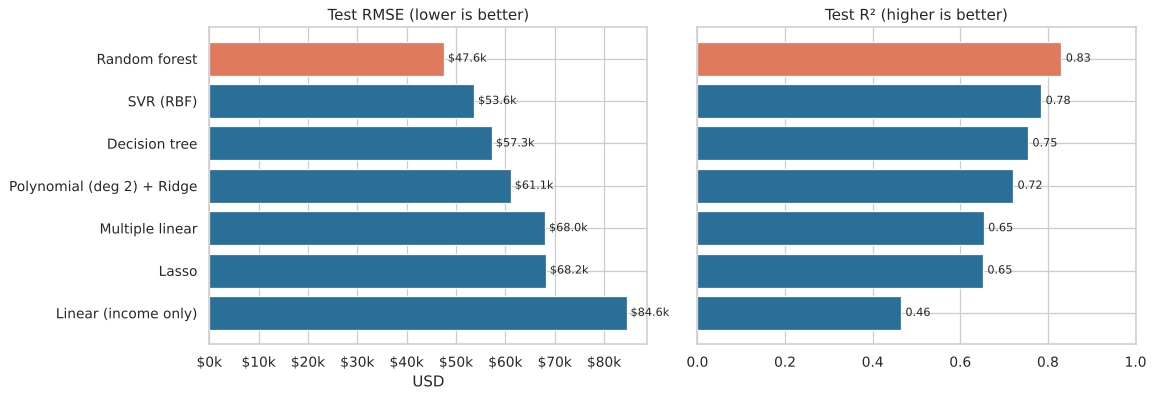

,RMSE,MAE,R²
Random forest,"$47,557","$31,766",0.831
SVR (RBF),"$53,633","$35,077",0.785
Decision tree,"$57,275","$38,657",0.755
Polynomial (deg 2) + Ridge,"$61,101","$43,348",0.721
Multiple linear,"$68,041","$49,023",0.654
Lasso,"$68,211","$49,065",0.652
Linear (income only),"$84,570","$63,231",0.465


In [16]:
table = pd.DataFrame(results).T.sort_values("RMSE")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
colors = [PALETTE[1] if n == table.index[0] else PALETTE[0] for n in table.index]
axes[0].barh(table.index[::-1], table["RMSE"][::-1], color=colors[::-1])
for i, v in enumerate(table["RMSE"][::-1]):
    axes[0].text(v + 800, i, f"${v/1000:,.1f}k", va="center", fontsize=9)
axes[0].set(title="Test RMSE (lower is better)", xlabel="USD")
axes[0].xaxis.set_major_formatter(lambda v, _: f"${v/1000:,.0f}k")
axes[1].barh(table.index[::-1], table["R²"][::-1], color=colors[::-1])
for i, v in enumerate(table["R²"][::-1]):
    axes[1].text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=9)
axes[1].set(title="Test R² (higher is better)", xlim=(0, 1)); axes[1].set_yticklabels([])
plt.tight_layout(); plt.savefig(FIG + "06_model_comparison.png", dpi=150); plt.show()
table.style.format({"RMSE": "${:,.0f}", "MAE": "${:,.0f}", "R²": "{:.3f}"})

## 5. Best model: Random forest

Half of test districts are predicted within $20,409.
Capped districts (actual = $500,001): mean error $64,515 vs $30,133 for the rest.


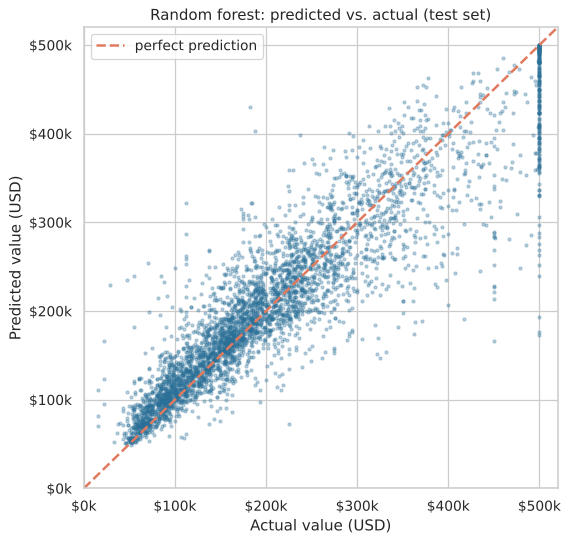

In [17]:
rf_search, rf_pred = fitted["Random forest"]
fig, ax = plt.subplots(figsize=(6.5, 6.2))
ax.scatter(y_test, rf_pred, s=6, alpha=0.3, color=PALETTE[0])
lims = [0, 520_000]
ax.plot(lims, lims, "--", color=PALETTE[1], lw=2, label="perfect prediction")
ax.set(xlim=lims, ylim=lims, title="Random forest: predicted vs. actual (test set)",
       xlabel="Actual value (USD)", ylabel="Predicted value (USD)")
for axis in (ax.xaxis, ax.yaxis): axis.set_major_formatter(lambda v, _: f"${v/1000:,.0f}k")
ax.legend(loc="upper left")
plt.tight_layout(); plt.savefig(FIG + "07_rf_predicted_vs_actual.png", dpi=150); plt.show()

err = (rf_pred - y_test).abs()
print(f"Half of test districts are predicted within ${err.median():,.0f}.")
print(f"Capped districts (actual = $500,001): mean error ${err[y_test >= 500_001].mean():,.0f} vs ${err[y_test < 500_001].mean():,.0f} for the rest.")

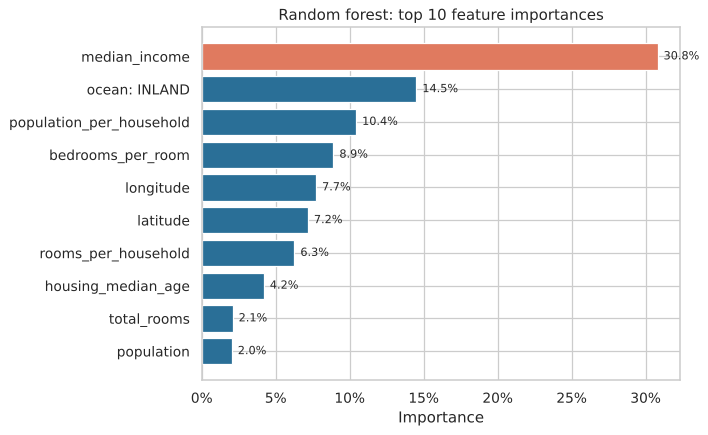

In [18]:
best = rf_search.best_estimator_
names = best.named_steps["prep"].named_steps["columns"].get_feature_names_out()
names = [n.split("__", 1)[1].replace("ocean_proximity_", "ocean: ") for n in names]
imp = pd.Series(best.named_steps["model"].feature_importances_, index=names).sort_values()
top = imp.tail(10)
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top.values, color=[PALETTE[1] if v == top.max() else PALETTE[0] for v in top.values])
for i, v in enumerate(top.values):
    ax.text(v + 0.004, i, f"{v:.1%}", va="center", fontsize=9)
ax.set(title="Random forest: top 10 feature importances", xlabel="Importance")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.tight_layout(); plt.savefig(FIG + "08_feature_importance.png", dpi=150); plt.show()

## 6. Key findings

In [19]:
rf = results["Random forest"]; base = results["Linear (income only)"]
print(f"1. Income is the #1 driver: r = {df.median_income.corr(df.median_house_value):.2f}; "
      f"top-income districts are {by_q.iloc[-1] / by_q.iloc[0]:.1f}× pricier than bottom-income ones.")
print(f"2. Location matters almost as much: coastal districts are {coastal / inland:.1f}× more expensive than inland; "
      f"inland is the single most important location feature.")
print(f"3. Ratio features beat raw counts: bedrooms_per_room (r = {eng.bedrooms_per_room.corr(eng.median_house_value):.2f}) "
      f"vs total_bedrooms (r = {df.total_bedrooms.corr(df.median_house_value):.2f}).")
print(f"4. Random forest is the best model: R² = {rf['R²']:.2f}, typical error (MAE) ${rf['MAE']:,.0f}, "
      f"RMSE {100 * (1 - rf['RMSE'] / base['RMSE']):.0f}% lower than an income-only linear baseline.")
print(f"5. Limitation: the $500,001 price cap means no model can value the most expensive districts correctly.")

1. Income is the #1 driver: r = 0.69; top-income districts are 3.2× pricier than bottom-income ones.
2. Location matters almost as much: coastal districts are 2.0× more expensive than inland; inland is the single most important location feature.
3. Ratio features beat raw counts: bedrooms_per_room (r = -0.26) vs total_bedrooms (r = 0.05).
4. Random forest is the best model: R² = 0.83, typical error (MAE) $31,766, RMSE 44% lower than an income-only linear baseline.
5. Limitation: the $500,001 price cap means no model can value the most expensive districts correctly.


**Possible next steps:** gradient boosting (XGBoost / LightGBM), distance-to-city features, and treating capped districts separately (e.g. a censored-regression approach).